In [1]:
# ============================================================
# CELL 0 — Install Required Packages
# ============================================================

%pip install -q shap

Note: you may need to restart the kernel to use updated packages.


In [1]:

# ============================================================
# CELL 1 — Setup + Paths (Final Checkpoint)
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv
import shap

# Resolve the project root from the current notebook directory.
ROOT = Path.cwd()

while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

MODEL_DIR = ROOT / "models"
GRAPH_DIR = ROOT / "graph"
DATA_DIR = ROOT / "data" / "processed"
METRICS_DIR = ROOT / "metrics"
XAI_DIR = ROOT / "xai"

XAI_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "best_improved_gat_lstm.pt"
CFG_PATH = MODEL_DIR / "gat_lstm_config.pkl"
SCALER_PATH = MODEL_DIR / "feature_scaler.pkl"

TEST_PRED_PATH = MODEL_DIR / "gat_lstm_test_predictions.npy"
TEST_TARGET_PATH = MODEL_DIR / "gat_lstm_test_targets.npy"
TEST_MASK_PATH = MODEL_DIR / "gat_lstm_test_mask.npy"
TEST_TIMES_PATH = MODEL_DIR / "gat_lstm_test_times.npy"

REQUIRED_FILES = [
    MODEL_PATH,
    CFG_PATH,
    SCALER_PATH,
    DATA_DIR / "test.csv",
    GRAPH_DIR / "station_metadata_final.csv",
    GRAPH_DIR / "edge_index_final.csv",
    TEST_PRED_PATH,
    TEST_TARGET_PATH,
    TEST_MASK_PATH,
    TEST_TIMES_PATH,
]

missing_files = [str(p) for p in REQUIRED_FILES if not p.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required PolluSenseAI files are missing:\n"
        + "\n".join(missing_files)
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Improve reproducibility of the XAI sampling/explanation.
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("=" * 65)
print("POLLUSENSEAI XAI SETUP")
print("=" * 65)
print("Project root:", ROOT)
print("Device:", DEVICE)
print("Checkpoint:", MODEL_PATH)
print("Configuration:", CFG_PATH)
print("Feature scaler:", SCALER_PATH)


C:\Users\vabhi\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\vabhi\AppData\Roaming\Python\Python311\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


POLLUSENSEAI XAI SETUP
Project root: c:\Users\vabhi\Downloads\Implementation\Implementation
Device: cpu
Checkpoint: c:\Users\vabhi\Downloads\Implementation\Implementation\models\best_improved_gat_lstm.pt
Configuration: c:\Users\vabhi\Downloads\Implementation\Implementation\models\gat_lstm_config.pkl
Feature scaler: c:\Users\vabhi\Downloads\Implementation\Implementation\models\feature_scaler.pkl


In [2]:
# ============================================================
# CELL 2 — Load Configuration + Graph
# ============================================================

cfg = joblib.load(CFG_PATH)
scaler = joblib.load(SCALER_PATH)

FEATURES = cfg["features"]
TARGETS = cfg["targets"]
SEQ_LEN = cfg["seq_len"]
STATIONS = cfg["station_list"]

fill_values = np.asarray(
    cfg["fill_values"],
    dtype=np.float32
)

target_mean = np.asarray(cfg["target_mean"])
target_std = np.asarray(cfg["target_std"])
res_mean = np.asarray(cfg["res_mean"])
res_std = np.asarray(cfg["res_std"])

AQI_BP = cfg["aqi_breakpoints"]
AQI_WINDOW_HOURS = cfg.get(
    "aqi_window_hours",
    {
        "co": 8, "o3": 8,
        "no2": 24, "pm10": 24,
        "pm25": 24, "so2": 24,
    }
)

stations = pd.read_csv(
    GRAPH_DIR / "station_metadata_final.csv"
)

edges = pd.read_csv(
    GRAPH_DIR / "edge_index_final.csv"
)

idx = {s: i for i, s in enumerate(STATIONS)}
N = len(STATIONS)

EDGE_INDEX = torch.tensor(
    np.stack([
        edges.source.map(idx),
        edges.target.map(idx)
    ]),
    dtype=torch.long,
    device=DEVICE
)

# Preserve the raw distance attributes used in Notebook 7.
EDGE_ATTR = torch.tensor(
    edges.distance_km.to_numpy(),
    dtype=torch.float32,
    device=DEVICE
).view(-1, 1)

print(f"Stations: {N} | Edges: {EDGE_INDEX.shape[1]}")
print(f"Features: {len(FEATURES)} | Targets: {len(TARGETS)}")
print("Sequence length:", SEQ_LEN)


# ------------------------------------------------------------
# Validate the configuration against the final Notebook 7 model
# ------------------------------------------------------------

EXPECTED_TARGETS = ["co", "no2", "o3", "pm10", "pm25", "so2"]

if list(TARGETS) != EXPECTED_TARGETS:
    raise ValueError(
        f"Target order mismatch. Saved config: {TARGETS}"
    )

if len(FEATURES) != 34:
    raise ValueError(
        f"Expected 34 base features, got {len(FEATURES)}."
    )

if len(STATIONS) != 37:
    raise ValueError(
        f"Expected 37 stations, got {len(STATIONS)}."
    )

if int(SEQ_LEN) != 24:
    raise ValueError(
        f"Expected 24 input timesteps, got {SEQ_LEN}."
    )

if fill_values.shape != (len(FEATURES),):
    raise ValueError("Saved feature-fill values have an unexpected shape.")

for name, values in [
    ("target_mean", target_mean),
    ("target_std", target_std),
    ("res_mean", res_mean),
    ("res_std", res_std),
]:
    if values.shape != (len(TARGETS),):
        raise ValueError(
            f"{name} should contain one value per target; got {values.shape}."
        )

if not np.isfinite(res_mean).all() or not np.isfinite(res_std).all():
    raise ValueError("Saved residual scaling values contain non-finite values.")

if (res_std <= 0).any() or (target_std <= 0).any():
    raise ValueError("Saved target/residual scaling contains non-positive std.")

if EDGE_INDEX.ndim != 2 or EDGE_INDEX.shape[0] != 2:
    raise ValueError(f"Unexpected edge-index shape: {EDGE_INDEX.shape}")

if EDGE_ATTR.shape != (EDGE_INDEX.shape[1], 1):
    raise ValueError(f"Unexpected edge-attribute shape: {EDGE_ATTR.shape}")

if EDGE_INDEX.numel() == 0:
    raise ValueError("The station graph has no edges.")

if EDGE_INDEX.min().item() < 0 or EDGE_INDEX.max().item() >= N:
    raise ValueError("Graph contains station indices outside the valid range.")

if not torch.isfinite(EDGE_ATTR).all():
    raise ValueError("Graph edge attributes contain non-finite values.")

print("\nConfiguration and graph checks passed.")
print("Base features:", len(FEATURES))
print("Model input channels:", len(FEATURES) + 2 * len(TARGETS))
print("Stations:", N)
print("Directed edges:", EDGE_INDEX.shape[1])


Stations: 37 | Edges: 169
Features: 34 | Targets: 6
Sequence length: 24

Configuration and graph checks passed.
Base features: 34
Model input channels: 46
Stations: 37
Directed edges: 169


In [3]:
# ============================================================
# CELL 3 — Load Trained Residual GAT-LSTM
# ============================================================

INPUT_DIM, HIDDEN, HEADS, DROP = 46, 128, 4, 0.2

class ResidualGATLSTM(nn.Module):
    def __init__(self,Fdim,hidden=128,heads=4,drop=0.2):
        super().__init__()
        self.lstm = nn.LSTM(Fdim,hidden,2,batch_first=True,dropout=drop)
        self.emb = nn.Embedding(N,16)
        self.gat1 = GATv2Conv(hidden+16,hidden//heads,heads=heads,edge_dim=1)
        self.gat2 = GATv2Conv(hidden,hidden,edge_dim=1)
        self.n1 = nn.LayerNorm(hidden)
        self.n2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(drop)
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden,64),nn.SiLU(),
                nn.Dropout(drop),nn.Linear(64,1)
            ) for _ in TARGETS
        ])

    def forward(self,x,edge_index,edge_attr):
        B,T,Nn,Fdim = x.shape
        z = x.permute(0,2,1,3).reshape(B*Nn,T,Fdim)
        h,_ = self.lstm(z)
        h = h[:,-1].view(B,Nn,-1)

        
        e = self.emb(
            torch.arange(Nn, device=h.device)
        ).unsqueeze(0).expand(B, -1, -1)

        h = torch.cat([h, e], dim=-1).reshape(B * Nn, -1)

        # Use the graph supplied to forward(), repeated for each batch item.
        base_edge_index = edge_index.to(h.device)
        base_edge_attr = edge_attr.to(h.device)

        if base_edge_index.ndim != 2 or base_edge_index.shape[0] != 2:
            raise ValueError("edge_index must have shape (2, E).")

        if base_edge_attr.shape != (base_edge_index.shape[1], 1):
            raise ValueError("edge_attr must have shape (E, 1).")

        offsets = torch.arange(B, device=h.device) * Nn

        ei = torch.cat(
            [base_edge_index + offset for offset in offsets],
            dim=1,
        )

        ea = base_edge_attr.repeat(B, 1)

        z = F.elu(self.gat1(h,ei,edge_attr=ea))
        z = self.drop(self.n1(z))
        z = self.gat2(z,ei,edge_attr=ea)
        z = self.n2(z+h[:,:z.shape[1]])
        z = self.drop(z).view(B,Nn,-1)

        return torch.cat([head(z) for head in self.heads],-1)

model = ResidualGATLSTM(INPUT_DIM).to(DEVICE)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=DEVICE),
    strict=True,
)
model.eval()

print("Trained model loaded.")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Trained model loaded.
Parameters: 344,150


In [4]:
# ============================================================
# CELL 4 — Build Historical 24-Hour Test Window
# ============================================================


# ============================================================
# CELL 4 — Build Historical 24-Hour Test Window
# ============================================================

test_df = pd.read_csv(DATA_DIR / "test.csv")

# Use timezone-naive UTC consistently for exact timestamp matching.
test_df["datetime_utc"] = (
    pd.to_datetime(test_df["datetime_utc"], utc=True)
    .dt.tz_localize(None)
)

test_df["location_id"] = test_df["location_id"].astype(str)
test_df = test_df[
    test_df["location_id"].isin(STATIONS)
].copy()

if test_df.duplicated(["datetime_utc", "location_id"]).any():
    raise ValueError(
        "test.csv contains duplicate timestamp/station rows."
    )

times = pd.DatetimeIndex(
    test_df["datetime_utc"].drop_duplicates().sort_values()
)

if len(times) <= SEQ_LEN:
    raise ValueError(
        "The test split does not contain enough hourly timestamps."
    )

# Explain the final test prediction, using the preceding 24 hours.
TARGET_TIME = pd.Timestamp(times[-1])

WINDOW = pd.date_range(
    start=TARGET_TIME - pd.Timedelta(hours=SEQ_LEN),
    end=TARGET_TIME - pd.Timedelta(hours=1),
    freq="h",
)

if len(WINDOW) != SEQ_LEN:
    raise ValueError(
        f"Expected {SEQ_LEN} input hours, got {len(WINDOW)}."
    )

mi = pd.MultiIndex.from_product(
    [WINDOW, STATIONS],
    names=["datetime_utc", "location_id"],
)

d = (
    test_df
    .set_index(["datetime_utc", "location_id"])
    .reindex(mi)
)

print("Target time:", TARGET_TIME)
print("Input window:", WINDOW[0], "→", WINDOW[-1])
print("Input rows:", len(d))

# ------------------------------------------------------------
# Base features: training fill values -> saved scaler
# ------------------------------------------------------------

X = d[FEATURES].to_numpy(np.float32)

missing_rows, missing_cols = np.where(
    ~np.isfinite(X)
)

X[missing_rows, missing_cols] = fill_values[missing_cols]

X = scaler.transform(X).astype(np.float32)

X = X.reshape(
    SEQ_LEN, N, len(FEATURES)
)

# ------------------------------------------------------------
# Pollutant history channels and availability masks
# ------------------------------------------------------------

Y_raw = d[TARGETS].to_numpy(np.float32).reshape(
    SEQ_LEN, N, len(TARGETS)
)

M = np.isfinite(Y_raw).astype(np.float32)

# Match Notebook 7: scale the targets before replacing
# missing scaled values with zero.
Y_scaled = (Y_raw - target_mean) / target_std

Y_scaled = np.nan_to_num(
    Y_scaled,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
).astype(np.float32)

X46 = np.concatenate(
    [X, Y_scaled, M],
    axis=-1
).astype(np.float32)

xseq = torch.tensor(
    X46[None],
    dtype=torch.float32,
    device=DEVICE
)

print("Target time:", TARGET_TIME)
print("Window:", WINDOW[0], "→", WINDOW[-1])
print("Input shape:", tuple(xseq.shape))
print("Missing values:", np.isnan(X46).sum())
print("Finite input:", bool(np.isfinite(X46).all()))

assert xseq.shape == (1, 24, N, 46)
assert np.isfinite(X46).all()

Target time: 2025-12-31 21:00:00
Input window: 2025-12-30 21:00:00 → 2025-12-31 20:00:00
Input rows: 888
Target time: 2025-12-31 21:00:00
Window: 2025-12-30 21:00:00 → 2025-12-31 20:00:00
Input shape: (1, 24, 37, 46)
Missing values: 0
Finite input: True


In [5]:

# ============================================================
# CELL 5 — Select Prediction + Verify Notebook 7 Alignment
# ============================================================

STATION = "ST01"
POLLUTANT = "pm25"

if STATION not in STATIONS:
    raise ValueError(f"Unknown station: {STATION}")

if POLLUTANT not in TARGETS:
    raise ValueError(f"Unknown pollutant: {POLLUTANT}")

si = STATIONS.index(STATION)
pi = TARGETS.index(POLLUTANT)

previous_time = TARGET_TIME - pd.Timedelta(hours=1)

last_raw = d.loc[(previous_time, STATION), POLLUTANT]

if not np.isfinite(last_raw):
    raise ValueError(
        f"Cannot reconstruct {POLLUTANT} prediction for {STATION}: "
        f"the preceding-hour concentration at {previous_time} is missing. "
        "Choose a station with a valid preceding-hour concentration."
    )

actual_rows = test_df.loc[
    (test_df["datetime_utc"] == TARGET_TIME)
    & (test_df["location_id"] == STATION),
    POLLUTANT,
]

if len(actual_rows) != 1 or not np.isfinite(actual_rows.iloc[0]):
    raise ValueError(
        f"No unique, valid actual {POLLUTANT} value exists for "
        f"{STATION} at {TARGET_TIME}. Choose another valid sample."
    )

actual = float(actual_rows.iloc[0])

with torch.no_grad():
    residual_scaled = model(
        xseq,
        EDGE_INDEX,
        EDGE_ATTR,
    )[0, si, pi].item()

prediction = (
    residual_scaled * res_std[pi]
    + res_mean[pi]
    + float(last_raw)
)

UNIT = "mg/m³" if POLLUTANT == "co" else "µg/m³"

# ------------------------------------------------------------
# Cross-check against the final saved Notebook 7 predictions
# ------------------------------------------------------------

saved_pred = np.load(TEST_PRED_PATH, allow_pickle=False)
saved_true = np.load(TEST_TARGET_PATH, allow_pickle=False)
saved_mask = np.load(TEST_MASK_PATH, allow_pickle=False).astype(bool)

saved_time_values = np.load(
    TEST_TIMES_PATH,
    allow_pickle=False,
)

saved_times = pd.DatetimeIndex(
    pd.to_datetime(saved_time_values, utc=True).tz_localize(None)
)

if not (
    saved_pred.shape == saved_true.shape == saved_mask.shape
):
    raise ValueError(
        "Notebook 7 prediction, target and mask shapes do not match."
    )

matching_time_idx = np.flatnonzero(saved_times == TARGET_TIME)

if len(matching_time_idx) != 1:
    raise ValueError(
        f"Expected one saved prediction timestamp for {TARGET_TIME}; "
        f"found {len(matching_time_idx)}."
    )

test_idx = int(matching_time_idx[0])

if not saved_mask[test_idx, si, pi]:
    raise ValueError(
        f"Notebook 7's saved test mask marks {STATION}/{POLLUTANT} "
        f"at {TARGET_TIME} as invalid."
    )

reference_prediction = float(saved_pred[test_idx, si, pi])
reference_actual = float(saved_true[test_idx, si, pi])

if not np.isclose(
    prediction,
    reference_prediction,
    rtol=1e-5,
    atol=1e-5,
):
    raise ValueError(
        "XAI prediction does not match Notebook 7's saved prediction. "
        f"XAI={prediction:.8f}; Notebook 7={reference_prediction:.8f}. "
        "Check the input scaler, graph, and 24-hour sequence."
    )

if not np.isfinite(reference_actual) or not np.isclose(
    actual,
    reference_actual,
    rtol=1e-5,
    atol=1e-5,
):
    raise ValueError(
        "XAI actual concentration does not match Notebook 7's saved "
        "test target. Recheck test timestamps and station ordering."
    )

print("=" * 65)
print("XAI SAMPLE VERIFIED AGAINST NOTEBOOK 7")
print("=" * 65)
print("Target time:", TARGET_TIME)
print("Station:", STATION)
print("Pollutant:", POLLUTANT.upper())
print(f"Prediction: {prediction:.5f} {UNIT}")
print(f"Saved prediction: {reference_prediction:.5f} {UNIT}")
print(f"Actual: {actual:.5f} {UNIT}")
print(f"Saved actual: {reference_actual:.5f} {UNIT}")
print(f"Error: {prediction - actual:+.5f} {UNIT}")
print("PASS: Exact timestamp, station, target and prediction verified.")


XAI SAMPLE VERIFIED AGAINST NOTEBOOK 7
Target time: 2025-12-31 21:00:00
Station: ST01
Pollutant: PM25
Prediction: 367.35141 µg/m³
Saved prediction: 367.35141 µg/m³
Actual: 448.00000 µg/m³
Saved actual: 448.00000 µg/m³
Error: -80.64859 µg/m³
PASS: Exact timestamp, station, target and prediction verified.


In [6]:
# ============================================================
# CELL 6 — GAT Spatial Explanation
# ============================================================

with torch.no_grad():
    B,T,Nn,Fdim = xseq.shape
    z = xseq.permute(0,2,1,3).reshape(B*Nn,T,Fdim)
    h,_ = model.lstm(z)
    h = h[:,-1].view(B,Nn,-1)

    e = model.emb(torch.arange(N,device=DEVICE)).unsqueeze(0).expand(B,-1,-1)
    h = torch.cat([h,e],-1).reshape(B*Nn,-1)

    z1 = F.elu(model.gat1(h,EDGE_INDEX,edge_attr=EDGE_ATTR))
    z1 = model.drop(model.n1(z1))

    _,(ei,att) = model.gat2(
        z1,EDGE_INDEX,edge_attr=EDGE_ATTR,
        return_attention_weights=True
    )

a = att.mean(-1).cpu().numpy()
ei = ei.cpu().numpy()

incoming = [
    (STATIONS[s],float(a[j]))
    for j,s in enumerate(ei[0])
    if ei[1,j]==si and s!=si
]

attention = (
    pd.DataFrame(incoming,columns=["station","attention"])
    .groupby("station").attention.mean()
    .sort_values(ascending=False)
)

print("Top spatial contributors:")
print(attention.head(10).to_string())

Top spatial contributors:
station
ST20    0.334441
ST11    0.258854
ST07    0.224945
ST28    0.050892


In [7]:
# ============================================================
# CELL 7 — SHAP Feature Explanation
# ============================================================

base = xseq[0].detach().clone()


class SHAPWrapper(nn.Module):

    def __init__(
        self,
        model,
        base,
        station,
        target,
        res_mean_value,
        res_std_value,
        last_value,
    ):
        super().__init__()

        self.model = model
        self.base = base
        self.station = station
        self.target = target

        self.res_mean_value = float(res_mean_value)
        self.res_std_value = float(res_std_value)
        self.last_value = float(last_value)

    def forward(self, x):

        z = self.base.unsqueeze(0).repeat(
            x.shape[0], 1, 1, 1
        )

        # Explain the selected station's final-timestep inputs.
        z[:, -1, self.station, :] = x

        residual_scaled = self.model(
            z, EDGE_INDEX, EDGE_ATTR
        )[:, self.station, self.target]

        # Reconstruct the final pollutant concentration.
        prediction = (
            residual_scaled * self.res_std_value
            + self.res_mean_value
            + self.last_value
        )

        return prediction.unsqueeze(1)


STATION = "ST01"
POLLUTANT = "pm25"

si = STATIONS.index(STATION)
pi = TARGETS.index(POLLUTANT)

last_raw = d.loc[
    (
        TARGET_TIME - pd.Timedelta(hours=1),
        STATION
    ),
    POLLUTANT
]

if not np.isfinite(last_raw):
    raise ValueError(
        f"Cannot reconstruct {POLLUTANT} for {STATION}: "
        "the preceding-hour concentration is missing."
    )

wrapper = SHAPWrapper(
    model=model,
    base=base,
    station=si,
    target=pi,
    res_mean_value=res_mean[pi],
    res_std_value=res_std[pi],
    last_value=last_raw,
).eval()

# Background samples are the selected station's final eight
# historical feature vectors.
background = xseq[0, -8:, si, :].detach()

current = xseq[0, -1, si, :].detach().unsqueeze(0)

explainer = shap.GradientExplainer(
    wrapper,
    background
)

sv = np.squeeze(
    np.asarray(explainer.shap_values(current))
)


if sv.shape != (xseq.shape[-1],):
    raise ValueError(
        f"Expected {xseq.shape[-1]} SHAP values, got {sv.shape}."
    )


feature_names = FEATURES + [
    f"{p}_history" for p in TARGETS
] + [
    f"{p}_available" for p in TARGETS
]

shap_df = pd.DataFrame({
    "feature": feature_names,
    "shap": sv
})

shap_df["abs_shap"] = shap_df.shap.abs()

shap_df = shap_df.sort_values(
    "abs_shap",
    ascending=False
)

print("Top SHAP features:")
print(
    shap_df.head(15)[["feature", "shap"]]
    .to_string(index=False)
)

UNIT = "mg/m³" if POLLUTANT == "co" else "µg/m³"

print("\nSHAP output unit:", UNIT)

Top SHAP features:
       feature      shap
    co_history 12.701221
  pm10_history  2.797020
     pm25_lag1 -2.666026
  pm25_history -1.733242
   so2_history  0.754082
     pm10_lag1 -0.652092
       co_lag1  0.575378
      co_lag24 -0.491634
   no2_history -0.374651
    o3_history -0.227120
co_roll24_mean -0.197762
      so2_lag1 -0.192144
    pm25_lag24  0.170282
      no2_lag1  0.158857
          hour  0.156413

SHAP output unit: µg/m³


In [8]:
# ============================================================
# CELL 8 — Final XAI Explanation
# ============================================================

pos = (
    shap_df[shap_df.shap > 0]
    .sort_values("abs_shap", ascending=False)
    .head(3)
)

neg = (
    shap_df[shap_df.shap < 0]
    .sort_values("shap", ascending=True)
    .head(3)
)

print("=" * 68)
print("XAI EXPLANATION")
print("=" * 68)

print(f"Station    : {STATION}")
print(f"Pollutant  : {POLLUTANT.upper()}")
print(f"Prediction : {prediction:.2f} {UNIT}")
print(f"Actual     : {actual:.2f} {UNIT}")
print(f"Error      : {prediction - actual:+.2f} {UNIT}")

print("\nSpatial contributors:")
for i, (station, value) in enumerate(
    attention.head(3).items(), 1
):
    print(f"{i}. {station}: attention={value:.3f}")

print("\nPositive SHAP contributions:")
for _, row in pos.iterrows():
    print(
        f"{row.feature}: {row.shap:+.4f} {UNIT}"
    )

print("\nNegative SHAP contributions:")
for _, row in neg.iterrows():
    print(
        f"{row.feature}: {row.shap:+.4f} {UNIT}"
    )

print("\nInterpretation:")
print(
    "Positive SHAP values indicate input contributions that "
    "increase the prediction relative to the explainer's background."
)

print(
    "Negative SHAP values indicate input contributions that "
    "decrease the prediction relative to the explainer's background."
)

print(
    "GAT attention weights represent the model's relative learned "
    "weighting of incoming connected-station information for this "
    "input. They do not establish physical causation."
)

print("\nNatural-language explanation:")
print(
    f"For {STATION}, the GAT-LSTM predicted "
    f"{prediction:.2f} {UNIT} for {POLLUTANT.upper()}, "
    f"compared with an observed concentration of "
    f"{actual:.2f} {UNIT}. The leading positive feature "
    f"contributions were {', '.join(pos.feature)}; the leading "
    f"negative contributions were {', '.join(neg.feature)}. "
    f"The strongest incoming spatial-attention weights were "
    f"assigned to {', '.join(attention.head(3).index)}."
)

XAI EXPLANATION
Station    : ST01
Pollutant  : PM25
Prediction : 367.35 µg/m³
Actual     : 448.00 µg/m³
Error      : -80.65 µg/m³

Spatial contributors:
1. ST20: attention=0.334
2. ST11: attention=0.259
3. ST07: attention=0.225

Positive SHAP contributions:
co_history: +12.7012 µg/m³
pm10_history: +2.7970 µg/m³
so2_history: +0.7541 µg/m³

Negative SHAP contributions:
pm25_lag1: -2.6660 µg/m³
pm25_history: -1.7332 µg/m³
pm10_lag1: -0.6521 µg/m³

Interpretation:
Positive SHAP values indicate input contributions that increase the prediction relative to the explainer's background.
Negative SHAP values indicate input contributions that decrease the prediction relative to the explainer's background.
GAT attention weights represent the model's relative learned weighting of incoming connected-station information for this input. They do not establish physical causation.

Natural-language explanation:
For ST01, the GAT-LSTM predicted 367.35 µg/m³ for PM25, compared with an observed concentration

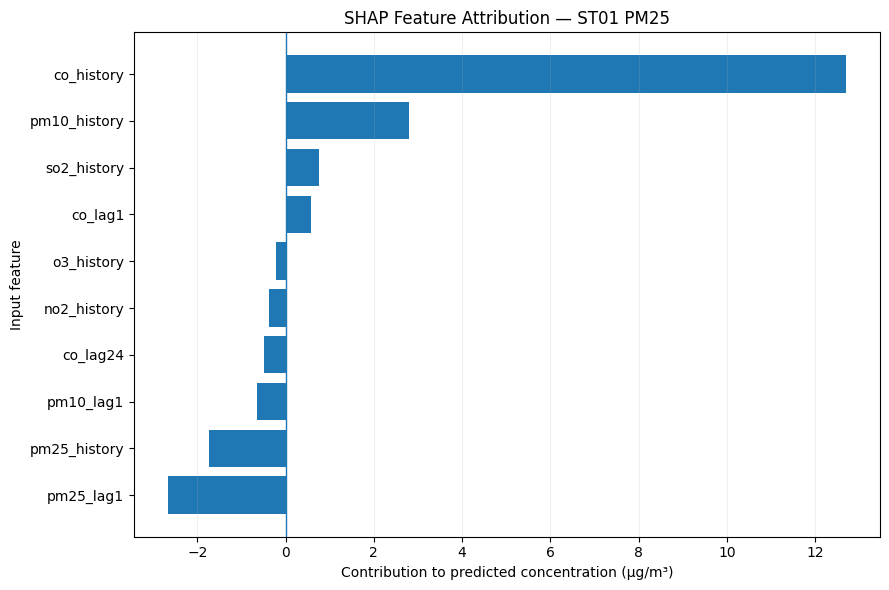

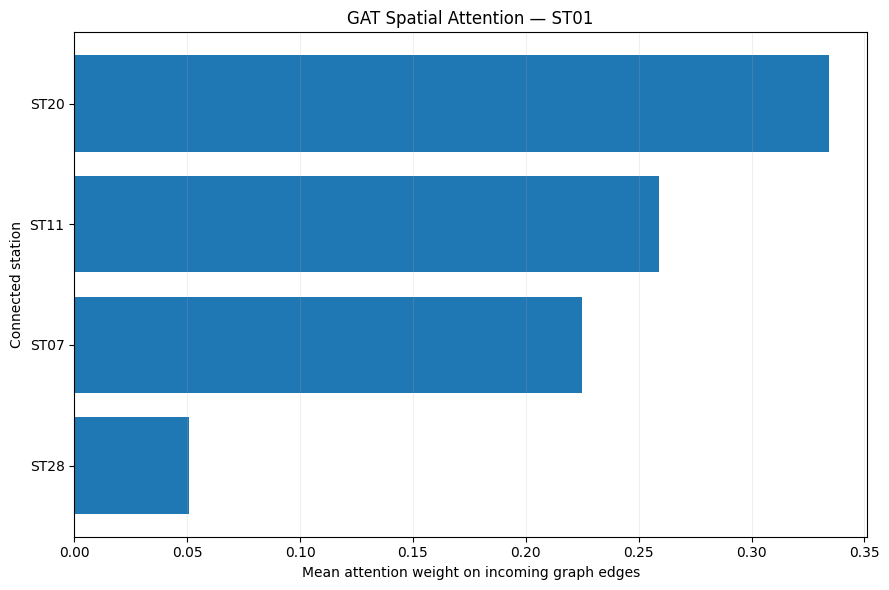

In [9]:
# ============================================================
# CELL 9 — XAI Visualizations
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# SHAP feature-attribution plot
# ------------------------------------------------------------

s = (
    shap_df.head(10)
    .sort_values("shap")
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(s.feature, s.shap)
ax.axvline(0, linewidth=1)

ax.set_title(
    f"SHAP Feature Attribution — {STATION} "
    f"{POLLUTANT.upper()}"
)

ax.set_xlabel(
    f"Contribution to predicted concentration ({UNIT})"
)

ax.set_ylabel(
    "Input feature"
)

ax.grid(axis="x", alpha=.2)

plt.tight_layout()

plt.savefig(
    XAI_DIR / "fig_xai_shap.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# GAT spatial-attention plot
# ------------------------------------------------------------

a = attention.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(a.index, a.values)

ax.set_title(
    f"GAT Spatial Attention — {STATION}"
)

ax.set_xlabel(
    "Mean attention weight on incoming graph edges"
)

ax.set_ylabel(
    "Connected station"
)

ax.grid(axis="x", alpha=.2)

plt.tight_layout()

plt.savefig(
    XAI_DIR / "fig_xai_spatial_attention.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [10]:
# ============================================================
# CELL 10 — Export Reusable XAI Module
# ============================================================

MODULE = r'''
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import shap


UNITS = {
    "co": "mg/m³",
    "no2": "µg/m³",
    "o3": "µg/m³",
    "pm10": "µg/m³",
    "pm25": "µg/m³",
    "so2": "µg/m³",
}


def _attention(
    model, xseq, edge_index, edge_attr, stations, si
):
    model.eval()

    with torch.no_grad():
        B, T, N, Fdim = xseq.shape

        z = xseq.permute(
            0, 2, 1, 3
        ).reshape(B * N, T, Fdim)

        h, _ = model.lstm(z)
        h = h[:, -1].view(B, N, -1)

        e = model.emb(
            torch.arange(N, device=h.device)
        ).unsqueeze(0).expand(B, -1, -1)

        h = torch.cat([h, e], -1).reshape(B * N, -1)

        z = F.elu(
            model.gat1(
                h, edge_index, edge_attr=edge_attr
            )
        )

        z = model.drop(model.n1(z))

        _, (ei, alpha) = model.gat2(
            z,
            edge_index,
            edge_attr=edge_attr,
            return_attention_weights=True,
        )

    ei = ei.cpu().numpy()
    alpha = alpha.mean(-1).cpu().numpy()

    rows = [
        (stations[src], float(alpha[j]))
        for j, src in enumerate(ei[0])
        if ei[1, j] == si and src != si
    ]

    if not rows:
        return pd.Series(dtype=float, name="attention")

    return (
        pd.DataFrame(
            rows, columns=["station", "attention"]
        )
        .groupby("station").attention.mean()
        .sort_values(ascending=False)
    )


class _Wrapper(nn.Module):

    def __init__(
        self,
        model,
        base,
        si,
        pi,
        edge_index,
        edge_attr,
        res_mean,
        res_std,
        last_value,
    ):
        super().__init__()

        self.model = model
        self.base = base

        self.si = si
        self.pi = pi

        self.edge_index = edge_index
        self.edge_attr = edge_attr

        self.res_mean = float(res_mean)
        self.res_std = float(res_std)
        self.last_value = float(last_value)

    def forward(self, x):

        z = self.base.unsqueeze(0).repeat(
            x.shape[0], 1, 1, 1
        )

        z[:, -1, self.si, :] = x

        residual_scaled = self.model(
            z,
            self.edge_index,
            self.edge_attr,
        )[:, self.si, self.pi]

        # Convert the explained model output into the final
        # pollutant concentration units.
        prediction = (
            residual_scaled * self.res_std
            + self.res_mean
            + self.last_value
        )

        return prediction.unsqueeze(1)


def explain_prediction(
    model,
    xseq,
    edge_index,
    edge_attr,
    stations,
    features,
    targets,
    station,
    pollutant,
    res_mean,
    res_std,
    last_value,
    background_hours=8,
    top_k=10,
):
    si = stations.index(station)
    pi = targets.index(pollutant)

    model.eval()

    with torch.no_grad():
        raw = model(
            xseq, edge_index, edge_attr
        )[0, si, pi].item()

    # Final predicted concentration in original units.
    prediction = (
        raw * float(res_std[pi])
        + float(res_mean[pi])
        + float(last_value)
    )

    base = xseq[0].detach()
    current = base[-1, si, :].unsqueeze(0)

    wrapper = _Wrapper(
        model,
        base,
        si,
        pi,
        edge_index,
        edge_attr,
        res_mean[pi],
        res_std[pi],
        last_value,
    ).eval()

    background = base[
        -background_hours:, si, :
    ]

    explainer = shap.GradientExplainer(
        wrapper,
        background,
    )

    sv = np.squeeze(
        np.asarray(explainer.shap_values(current))
    )

    names = (
        list(features)
        + [f"{p}_history" for p in targets]
        + [f"{p}_available" for p in targets]
    )

    shap_df = pd.DataFrame({
        "feature": names,
        "shap": sv,
    })

    shap_df["abs_shap"] = shap_df.shap.abs()

    shap_df = shap_df.sort_values(
        "abs_shap",
        ascending=False,
    )

    spatial = _attention(
        model,
        xseq,
        edge_index,
        edge_attr,
        stations,
        si,
    ).head(top_k)

    pos = (
        shap_df[shap_df.shap > 0]
        .sort_values("abs_shap", ascending=False)
        .head(3)
    )

    neg = (
        shap_df[shap_df.shap < 0]
        .sort_values("shap", ascending=True)
        .head(3)
    )

    unit = UNITS[pollutant]

    text = (
        f"For {station}, the GAT-LSTM predicted "
        f"{prediction:.2f} {unit} for {pollutant.upper()}. "
        f"Positive SHAP values indicate features that increased "
        f"the prediction relative to the explainer's background; "
        f"negative values indicate features that decreased it. "
        f"The leading positive contributors were "
        f"{', '.join(pos.feature)}. The leading negative "
        f"contributors were {', '.join(neg.feature)}. "
        f"The strongest incoming spatial-attention weights "
        f"were assigned to {', '.join(spatial.index[:3])}. "
        f"SHAP contributions and spatial attention describe "
        f"model behavior, not physical causation."
    )

    return {
        "station": station,
        "pollutant": pollutant,
        "prediction": float(prediction),
        "unit": unit,
        "shap_value_unit": unit,
        "spatial_attention": [
            {
                "station": str(s),
                "attention": float(v),
            }
            for s, v in spatial.items()
        ],
        "shap": [
            {
                "feature": str(r.feature),
                "value": float(r.shap),
            }
            for _, r in shap_df.head(top_k).iterrows()
        ],
        "top_positive_features": pos.feature.tolist(),
        "top_negative_features": neg.feature.tolist(),
        "natural_language": text,
    }
'''

(XAI_DIR / "pollusense_xai.py").write_text(
    MODULE,
    encoding="utf-8"
)

schema = {
    "station": "ST01",
    "pollutant": "pm25",
    "prediction": 0.0,
    "unit": "µg/m³",
    "shap_value_unit": "same as predicted concentration",
    "spatial_attention": [],
    "shap": [],
    "top_positive_features": [],
    "top_negative_features": [],
    "natural_language": "",
}

import json

(XAI_DIR / "frontend_response_schema.json").write_text(
    json.dumps(schema, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("✓", XAI_DIR / "pollusense_xai.py")
print("✓", XAI_DIR / "frontend_response_schema.json")

✓ c:\Users\vabhi\Downloads\Implementation\Implementation\xai\pollusense_xai.py
✓ c:\Users\vabhi\Downloads\Implementation\Implementation\xai\frontend_response_schema.json


In [11]:

# ============================================================
# CELL 11 — Final XAI Validation
# ============================================================

assert len(FEATURES) == 34
assert len(TARGETS) == 6
assert SEQ_LEN == 24
assert N == 37
assert EDGE_INDEX.shape[1] == 169
assert xseq.shape == (1, 24, 37, 46)

assert model.training is False
assert np.isfinite(X46).all()
assert np.isfinite(prediction)
assert np.isfinite(actual)
assert np.isclose(
    prediction,
    reference_prediction,
    rtol=1e-5,
    atol=1e-5,
)

expected_feature_names = (
    list(FEATURES)
    + [f"{p}_history" for p in TARGETS]
    + [f"{p}_available" for p in TARGETS]
)

assert len(expected_feature_names) == 46
assert shap_df["feature"].tolist() == shap_df.sort_values(
    "abs_shap", ascending=False
)["feature"].tolist()

assert len(shap_df) == 46
assert np.isfinite(shap_df["shap"].to_numpy(dtype=float)).all()
assert not attention.empty

# Check the exported explanation module exists and is syntactically valid.
XAI_MODULE_PATH = XAI_DIR / "pollusense_xai.py"
SCHEMA_PATH = XAI_DIR / "frontend_response_schema.json"

if not XAI_MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Reusable XAI module missing: {XAI_MODULE_PATH}"
    )

if not SCHEMA_PATH.exists():
    raise FileNotFoundError(
        f"Frontend response schema missing: {SCHEMA_PATH}"
    )

module_text = XAI_MODULE_PATH.read_text(encoding="utf-8")
compile(module_text, str(XAI_MODULE_PATH), "exec")

with SCHEMA_PATH.open("r", encoding="utf-8") as f:
    schema = json.load(f)

for key in [
    "station",
    "pollutant",
    "prediction",
    "unit",
    "spatial_attention",
    "shap",
    "natural_language",
]:
    assert key in schema, f"Schema missing key: {key}"

expected_figures = [
    XAI_DIR / "fig_xai_shap.png",
    XAI_DIR / "fig_xai_spatial_attention.png",
]

missing_figures = [str(p) for p in expected_figures if not p.exists()]

if missing_figures:
    raise FileNotFoundError(
        "Expected XAI figures are missing:\n"
        + "\n".join(missing_figures)
    )

print("=" * 65)
print("FINAL XAI VALIDATION PASSED")
print("=" * 65)
print("Checkpoint      :", MODEL_PATH)
print("Prediction time :", TARGET_TIME)
print("Station         :", STATION)
print("Pollutant       :", POLLUTANT.upper())
print("Features        :", len(FEATURES))
print("Model input     :", xseq.shape[-1])
print("Stations        :", N)
print("Directed edges  :", EDGE_INDEX.shape[1])
print("Sequence length :", SEQ_LEN)
print("SHAP values     :", len(shap_df))
print("Spatial entries :", len(attention))
print("Prediction alignment: PASS")
print("Reusable XAI module: PASS")
print("Visualization files: PASS")


FINAL XAI VALIDATION PASSED
Checkpoint      : c:\Users\vabhi\Downloads\Implementation\Implementation\models\best_improved_gat_lstm.pt
Prediction time : 2025-12-31 21:00:00
Station         : ST01
Pollutant       : PM25
Features        : 34
Model input     : 46
Stations        : 37
Directed edges  : 169
Sequence length : 24
SHAP values     : 46
Spatial entries : 4
Prediction alignment: PASS
Reusable XAI module: PASS
Visualization files: PASS
